## v1. Boundary trial: Meso (full) vs noMeso (W2.0)

Simple boundary test following `Run_parcels_UVW_3_sameSeed` (same fieldset settings, `time_periodic` = 31 days, RK4-3D, CheckError).
Three groups of 20 particles each, identical seeds in both velocity fields, tracked for 100 days:

* **coast**        : wet cells touching land (lateral boundary), near surface (0-7 m)
* **shelf_bottom** : shelf columns (W bottom 20-100 m), seeded one W level above the W bottom
* **ocean_bottom** : open ocean columns (W bottom > 3000 m), seeded one W level above the W bottom

Bottom seeds: `mbathy` = number of wet T levels, so the W bottom is `depthw[mbathy]` and the seed depth is `depthw[mbathy-1]` (top of the deepest wet cell, never below the sea bed).

What we look for: particles deleted (crash / out of bounds), frozen/stuck, above the surface, below the W bottom, on land, clashing (collapsing onto each other).

## 1. Parameters

In [1]:
n_per_group = 20
run_time_days = 100
time_step_minutes = 20
out_put_step_hours = 6

depth_min = 0      # coast group depth range
depth_max = 7

offset = 1
ref_date = "1993-01-01"
rdm_seed = 21      # one seed shared by both experiments

Hgr = "/work/bk1450/b383184/Amazon/Mercator/data/Hgr_cmesh.nc"
Zgr = "/work/bk1450/b383184/Amazon/Mercator/data/Zgr_cmesh2.nc"

experiments = {
    "Meso": {
        "U": "/work/bk1450/b383184/Amazon/Mercator/data/variables_c/UVW/U_1993-01c.nc",
        "V": "/work/bk1450/b383184/Amazon/Mercator/data/variables_c/UVW/V_1993-01c.nc",
        "W": "/work/bk1450/b383184/Amazon/Mercator/data/variables_c/UVW/W_1993-01fc.nc",
    },
    "noMeso": {
        "U": "/work/bk1450/b383184/Amazon/Mercator/implicit_run/output/W2.0/U_1993-01c_W2.0.nc",
        "V": "/work/bk1450/b383184/Amazon/Mercator/implicit_run/output/W2.0/V_1993-01c_W2.0.nc",
        "W": "/work/bk1450/b383184/Amazon/Mercator/implicit_run/output/W2.0/W_1993-01c_W2.0.nc",
    },
}

# boxes (lon0, lon1, lat0, lat1) where each group is drawn
box_shelf = (-52, -44, -2, 6)     # Amazon / Para shelf
box_ocean = (-48, -40, 2, 10)     # deep ocean offshore

In [2]:
import numpy as np
from datetime import timedelta
from parcels import FieldSet, ParticleSet, JITParticle, Variable, AdvectionRK4_3D

out_path = f'tracks_boundaries_{rdm_seed}/'
start_time = np.datetime64(ref_date) + np.timedelta64(offset, "D")
groups = ["coast", "shelf_bottom", "ocean_bottom"]
start_time

np.datetime64('1993-01-02')

## 2. Fieldsets (same settings as sameSeed)

In [3]:
loop_period = timedelta(days=31)

def make_fieldset(files):
    filenames = {
        v: {"data": files[v], "lon": Hgr, "lat": Hgr, "depth": files["W"]}
        for v in ["U", "V", "W"]
    }
    variables = {"U": "vozocrtx", "V": "vomecrty", "W": "vovecrtz"}
    dims = {"lon": "glamf", "lat": "gphif", "depth": "depthw", "time": "time_counter"}
    dimensions = {"U": dims, "V": dims, "W": dims}

    return FieldSet.from_nemo(
        filenames,
        variables,
        dimensions,
        deferred_load=True,
        allow_time_extrapolation=False,
        time_periodic=loop_period,
    )

fieldsets = {name: make_fieldset(files) for name, files in experiments.items()}

## 3. Model grid: land mask, W bottom, coast cells

In [4]:
import xarray as xr

_h = xr.open_dataset(Hgr)
_z = xr.open_dataset(Zgr)
glamt = _h.glamt.isel(t=0).values          # T points = cell centres
gphit = _h.gphit.isel(t=0).values
mbathy = _z.mbathy.isel(t=0).values.astype(int)   # wet T levels per column (0 = land)
depthw = xr.open_dataset(experiments["Meso"]["W"]).depthw.values
nz = len(depthw)

# W bottom of each column (the W level under the deepest wet T cell)
w_bottom = np.where(mbathy > 0, depthw[np.minimum(mbathy, nz - 1)], 0.0)

land = mbathy == 0
touches_land = np.zeros_like(land)
touches_land[1:-1, 1:-1] = land[:-2, 1:-1] | land[2:, 1:-1] | land[1:-1, :-2] | land[1:-1, 2:]

def in_box(b):
    return (glamt > b[0]) & (glamt < b[1]) & (gphit > b[2]) & (gphit < b[3])

kmin = int(np.searchsorted(depthw, depth_max))   # levels needed to hold depth_max
# interior only (edges of the domain excluded) and mbathy < nz so the W bottom exists
interior = np.zeros_like(land); interior[2:-2, 2:-2] = True

candidates = {
    "coast":        in_box(box_shelf) & interior & ~land & touches_land & (mbathy >= kmin),
    "shelf_bottom": in_box(box_shelf) & interior & ~land & ~touches_land & (w_bottom >= 20) & (w_bottom <= 100),
    "ocean_bottom": in_box(box_ocean) & interior & ~land & (w_bottom > 3000) & (mbathy < nz),
}
for g, m in candidates.items():
    print(f"{g:13s}: {m.sum()} candidate cells")

coast        : 215 candidate cells
shelf_bottom : 1495 candidate cells
ocean_bottom : 8687 candidate cells


## 4. Seeding — done ONCE, reused by both experiments

In [5]:
np.random.seed(rdm_seed)

start_lon, start_lat, start_depth, start_group = [], [], [], []
for gi, g in enumerate(groups):
    jj, ii = np.where(candidates[g])
    pick = np.random.choice(len(jj), n_per_group, replace=False)
    j, i = jj[pick], ii[pick]
    start_lon.append(glamt[j, i])
    start_lat.append(gphit[j, i])
    if g == "coast":
        start_depth.append(np.random.uniform(depth_min, depth_max, n_per_group))
    else:
        start_depth.append(depthw[mbathy[j, i] - 1])     # one W level above the W bottom
    start_group.append(np.full(n_per_group, gi))

start_lon = np.concatenate(start_lon)
start_lat = np.concatenate(start_lat)
start_depth = np.concatenate(start_depth)
start_group = np.concatenate(start_group)
num_particles = len(start_lon)
start_times = np.datetime64(start_time)

for gi, g in enumerate(groups):
    s = start_group == gi
    print(f"{g:13s}: depth {start_depth[s].min():8.2f} - {start_depth[s].max():8.2f} m")

coast        : depth     0.38 -     5.24 m
shelf_bottom : depth    19.99 -    71.56 m
ocean_bottom : depth  2696.58 -  4617.46 m


## 5. Land check (on both fieldsets) and sea-bed check

In [6]:
from scipy.spatial import cKDTree
_tree = cKDTree(np.c_[glamt.ravel(), gphit.ravel()])

def cell_of(lon, lat):
    _, k = _tree.query(np.c_[lon, lat])
    return np.unravel_index(k, glamt.shape)

j, i = cell_of(start_lon, start_lat)
assert np.all(start_depth < w_bottom[j, i]), "some seeds are below the W bottom"
print("all seeds above the W bottom")

# Land velocities are zeroed on load, so an exactly-zero UVW means a dry cell.
for name, fs in fieldsets.items():
    fs.computeTimeChunk(fs.U.grid.time[0], 1)
    _t = fs.U.grid.time[0]
    _dry = np.array([fs.UVW[_t, d, la, lo] == (0.0, 0.0, 0.0)
                     for lo, la, d in zip(start_lon, start_lat, start_depth)])
    print(f"{name}: " + ", ".join(f"{g} {_dry[start_group == gi].sum()}/{n_per_group}"
                                  for gi, g in enumerate(groups)) + " seeded on land")
    assert _dry.sum() == 0, f"{name}: some particles are on land" 

all seeds above the W bottom


Meso: coast 0/20, shelf_bottom 0/20, ocean_bottom 0/20 seeded on land


noMeso: coast 0/20, shelf_bottom 0/20, ocean_bottom 0/20 seeded on land


## 6. Run both experiments with the same starting positions

In [7]:
BoundaryParticle = JITParticle.add_variable(Variable("group", dtype=np.int32, to_write="once"))

##check the error: print what killed the particle, then delete it
def CheckError(particle, fieldset, time):
    if particle.state >= 50:  # This captures all Errors
        print("ERROR state=%d group=%d lon=%f lat=%f z=%f" % (particle.state, particle.group, particle.lon, particle.lat, particle.depth))
        particle.delete()

In [8]:
out_files = {}
for name, fs in fieldsets.items():
    print(f"--- running {name} ---")
    pset = ParticleSet(
        fieldset=fs,
        pclass=BoundaryParticle,
        lon=start_lon,
        lat=start_lat,
        depth=start_depth,
        time=start_times,
        group=start_group,
    )

    out_files[name] = out_path + f'Parcels_boundaries_{rdm_seed}_{name}_{start_time}.zarr'
    output_file = pset.ParticleFile(
        name=out_files[name],
        outputdt=timedelta(hours=out_put_step_hours),
        chunks=(num_particles, int(run_time_days*24/out_put_step_hours/4)),
    )

    pset.execute(
        [AdvectionRK4_3D, CheckError],
        runtime=timedelta(days=run_time_days),
        dt=timedelta(minutes=time_step_minutes),
        output_file=output_file,
    )

out_files

--- running Meso ---


INFO: Output files are stored in tracks_boundaries_21/Parcels_boundaries_21_Meso_1993-01-02.zarr.


  0%|          | 0/8640000.0 [00:00<?, ?it/s]

  0%|          | 1200.0/8640000.0 [00:00<53:10, 2708.01it/s]

  0%|          | 21600.0/8640000.0 [00:00<04:03, 35424.22it/s]

  0%|          | 43200.0/8640000.0 [00:02<09:20, 15347.94it/s]

... (801 outputs left out)

100%|█████████▉| 8618400.0/8640000.0 [08:51<00:01, 16875.73it/s]

100%|██████████| 8640000.0/8640000.0 [08:51<00:00, 19666.05it/s]

100%|██████████| 8640000.0/8640000.0 [08:51<00:00, 16246.95it/s]

{'Meso': 'tracks_boundaries_21/Parcels_boundaries_21_Meso_1993-01-02.zarr',
 'noMeso': 'tracks_boundaries_21/Parcels_boundaries_21_noMeso_1993-01-02.zarr'}

## 7. Diagnostics

In [9]:
import pandas as pd

ds = {name: xr.open_zarr(f).compute() for name, f in out_files.items()}
days = np.arange(ds["Meso"].sizes["obs"]) * out_put_step_hours / 24
n_obs_full = ds["Meso"].sizes["obs"]

def haversine_km(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.deg2rad, (lon1, lat1, lon2, lat2))
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

stuck_window = int(5 * 24 / out_put_step_hours)   # 5 days
rows, flags = [], {}
for name, d in ds.items():
    lon, lat, z = d.lon.values, d.lat.values, d.z.values
    grp = d.group.values
    valid = ~np.isnan(lat)
    n_valid = valid.sum(axis=1)

    # position -> model cell
    jj, ii = cell_of(np.nan_to_num(lon.ravel()), np.nan_to_num(lat.ravel()))
    wb = w_bottom[jj, ii].reshape(lon.shape)
    onland = (mbathy[jj, ii] == 0).reshape(lon.shape) & valid

    below_bed = (z > wb) & valid
    above_surf = (z < 0) & valid

    # frozen: moved < 50 m horizontally and < 0.1 m vertically over 5 days (while alive)
    dh = haversine_km(lon[:, :-stuck_window], lat[:, :-stuck_window], lon[:, stuck_window:], lat[:, stuck_window:])
    dz = np.abs(z[:, stuck_window:] - z[:, :-stuck_window])
    frozen = (dh < 0.05) & (dz < 0.1)

    # clashing: two particles closer than 100 m and 1 m in depth at the same output
    clash = np.zeros(lon.shape[0], dtype=bool)
    for t in range(lon.shape[1]):
        a = np.where(valid[:, t])[0]
        for p in range(len(a)):
            for q in range(p+1, len(a)):
                P, Q = a[p], a[q]
                if abs(z[P, t]-z[Q, t]) < 1 and haversine_km(lon[P, t], lat[P, t], lon[Q, t], lat[Q, t]) < 0.1:
                    clash[P] = clash[Q] = True

    f = dict(deleted=n_valid < n_obs_full, frozen=np.nansum(frozen, axis=1) > 0,
             below_bed=below_bed.any(axis=1), above_surface=above_surf.any(axis=1),
             on_land=onland.any(axis=1), clashing=clash)
    flags[name] = f
    for gi, g in enumerate(groups):
        s = grp == gi
        row = {"experiment": name, "group": g}
        row.update({k: int(v[s].sum()) for k, v in f.items()})
        row["alive_at_end"] = int(valid[s, -1].sum())
        row["max_z [m]"] = round(float(np.nanmax(z[s])), 1)
        rows.append(row)

summary = pd.DataFrame(rows).set_index(["experiment", "group"])
summary

deleted  frozen  below_bed  above_surface  on_land  \
experiment group                                                              
Meso       coast               0       2          1              0        0   
           shelf_bottom        0       0          0              0        0   
           ocean_bottom        0       0          0              0        0   
noMeso     coast               0       0          0              0        0   
           shelf_bottom        0       2          1              0        0   
           ocean_bottom        0       0          0              0        0   

                         clashing  alive_at_end  max_z [m]  
experiment group                                            
Meso       coast                0            20       73.4  
           shelf_bottom         0            20       89.4  
           ocean_bottom         0            20     4617.5  
noMeso     coast                0            20       13.4  
           shelf_bottom         0            20      110.1  
           ocean_bottom         0            20     4625.5

In [10]:
# details of every flagged particle
for name, f in flags.items():
    d = ds[name]
    for k, v in f.items():
        for p in np.where(v)[0]:
            last = np.where(~np.isnan(d.lat.values[p]))[0][-1]
            print(f"{name:7s} {k:13s} traj {p:2d} ({groups[int(d.group.values[p])]:12s}) "
                  f"last valid day {days[last]:6.2f} at lon {d.lon.values[p, last]:.3f} "
                  f"lat {d.lat.values[p, last]:.3f} z {d.z.values[p, last]:.1f}")

Meso    frozen        traj  8 (coast       ) last valid day  99.75 at lon -47.625 lat -0.041 z 25.5
Meso    frozen        traj 13 (coast       ) last valid day  99.75 at lon -59.635 lat 8.499 z 2.5
Meso    below_bed     traj  8 (coast       ) last valid day  99.75 at lon -47.625 lat -0.041 z 25.5
noMeso  frozen        traj 29 (shelf_bottom) last valid day  99.75 at lon -54.042 lat 7.190 z 30.2
noMeso  frozen        traj 36 (shelf_bottom) last valid day  99.75 at lon -47.792 lat 1.490 z 71.5
noMeso  below_bed     traj 29 (shelf_bottom) last valid day  99.75 at lon -54.042 lat 7.190 z 30.2


## 8. Plots

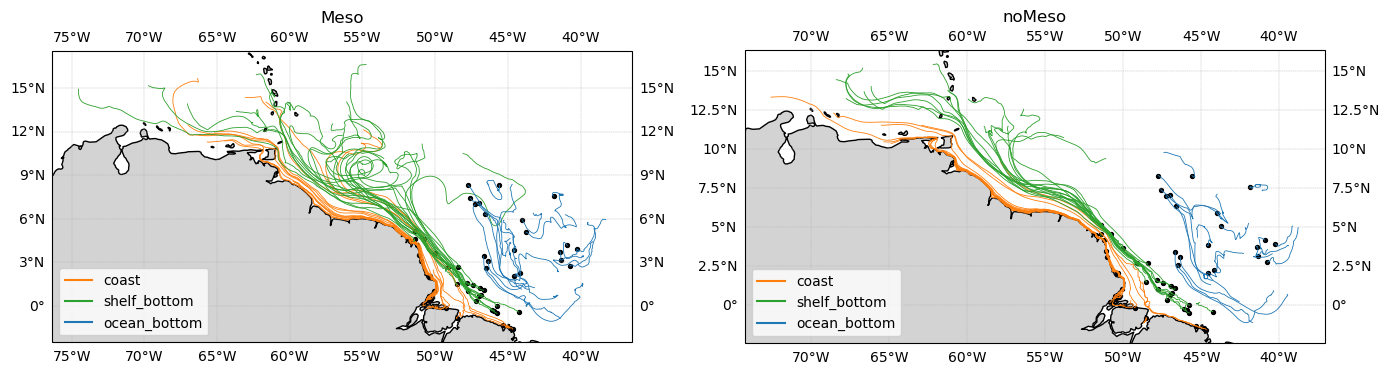

In [11]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

colors = {"coast": "tab:orange", "shelf_bottom": "tab:green", "ocean_bottom": "tab:blue"}
fig, axes = plt.subplots(1, 2, figsize=(14, 6), subplot_kw={"projection": ccrs.PlateCarree()})
for ax, (name, d) in zip(axes, ds.items()):
    ax.add_feature(cfeature.LAND, facecolor='lightgray')
    ax.coastlines(resolution='50m')
    ax.gridlines(draw_labels=True, linestyle='--', linewidth=0.3)
    for p in range(d.sizes["trajectory"]):
        g = groups[int(d.group.values[p])]
        ax.plot(d.lon[p], d.lat[p], lw=0.6, color=colors[g], transform=ccrs.PlateCarree())
        ax.scatter(start_lon[p], start_lat[p], s=8, color='k', transform=ccrs.PlateCarree())
    for g, c in colors.items():
        ax.plot([], [], color=c, label=g)
    ax.legend(loc='lower left')
    ax.set_title(name)
plt.tight_layout()
plt.show()

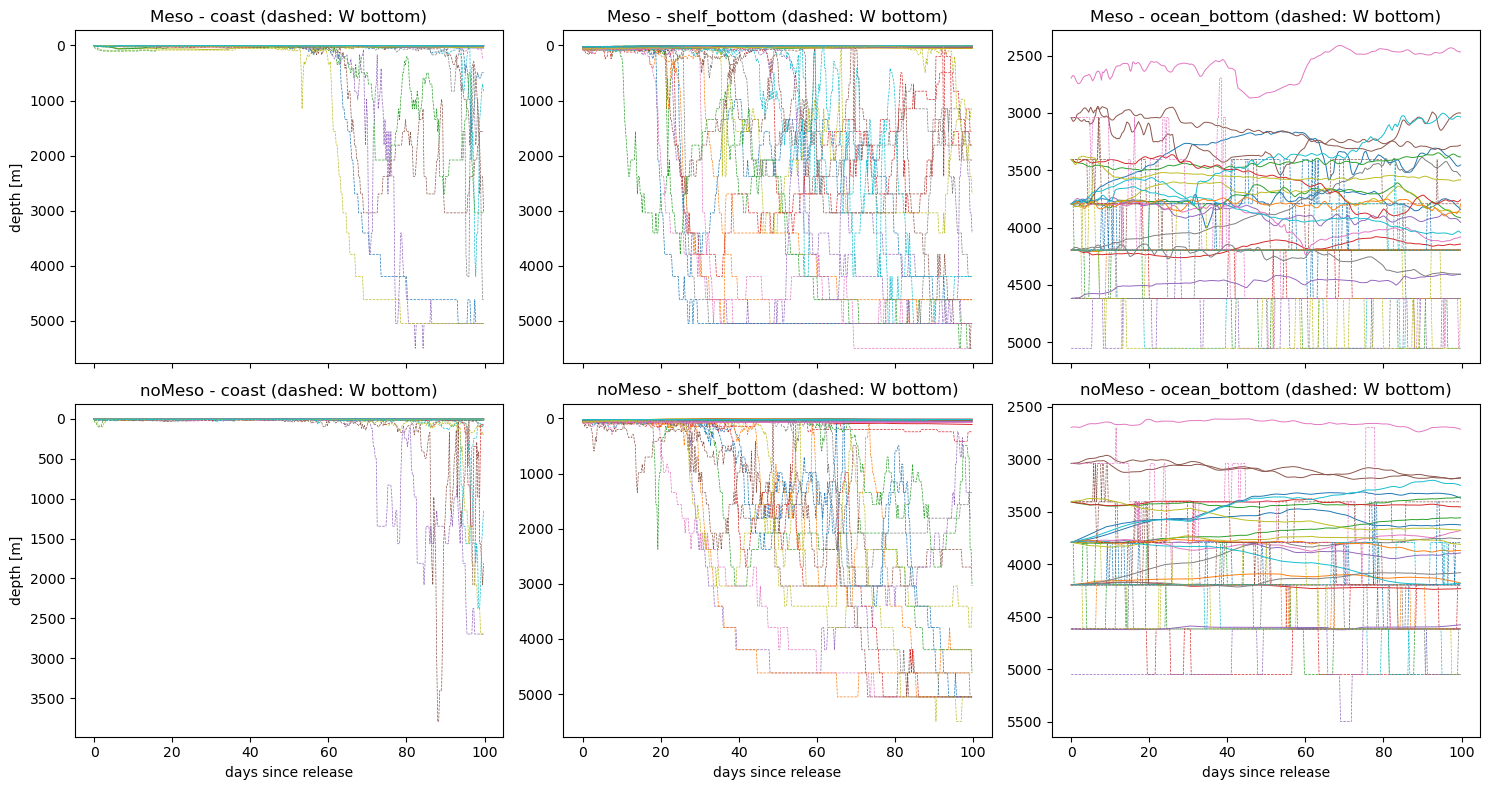

In [12]:
# depth of every particle vs the W bottom under it
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for r, (name, d) in enumerate(ds.items()):
    lon, lat, z = d.lon.values, d.lat.values, d.z.values
    jj, ii = cell_of(np.nan_to_num(lon.ravel()), np.nan_to_num(lat.ravel()))
    wb = np.where(np.isnan(lat), np.nan, w_bottom[jj, ii].reshape(lon.shape))
    for c, g in enumerate(groups):
        ax = axes[r, c]
        for p in np.where(d.group.values == c)[0]:
            l, = ax.plot(days, z[p], lw=0.7)
            ax.plot(days, wb[p], lw=0.5, ls='--', color=l.get_color())
        ax.invert_yaxis()
        ax.set_title(f"{name} - {g} (dashed: W bottom)")
        if c == 0: ax.set_ylabel('depth [m]')
for ax in axes[-1]: ax.set_xlabel('days since release')
plt.tight_layout()
plt.show()

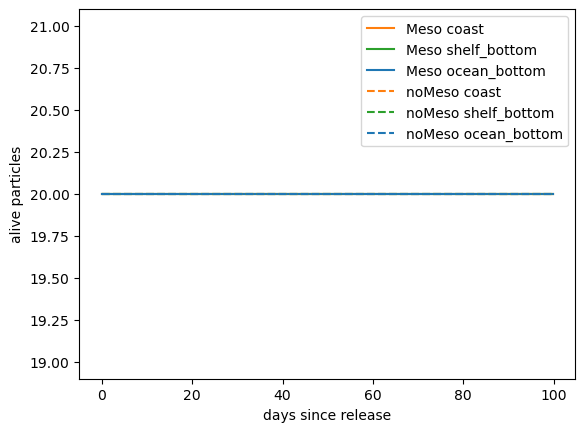

In [13]:
# particles still alive per group
fig, ax = plt.subplots()
for name, ls in zip(ds, ['-', '--']):
    d = ds[name]
    for gi, g in enumerate(groups):
        ax.plot(days, d.lat.notnull().values[d.group.values == gi].sum(axis=0), ls=ls, color=colors[g], label=f"{name} {g}")
ax.set_ylabel('alive particles'); ax.set_xlabel('days since release'); ax.legend()
plt.show()